In [ ]:
import os
%load_ext autoreload
%autoreload 1
%aimport utility.functions
%aimport src.analysis
%aimport src.dataset
%aimport src.plots
%aimport src.simulation
import numpy as np
import utility.functions as fn
import src.simulation as sim
import src.analysis as an
import src.dataset as ds
import src.plots as plots
import torch
from scipy.stats import norm
import pandas as pd
from utility.double_beta_spectrum import pdf_ratio2b
import glob
import matplotlib.pyplot as plt
BASE = "../"
channels = [3, 5, 9, 11, 13, 15, 17, 19]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]

Main loop to compute the BI for all channels and acceptance levels

In [ ]:
import sys
from pathlib import Path
# Add src to Python path dynamically
BASE = Path(__file__).resolve().parent.parent
sys.path.append(str(BASE))
import time
import numpy as np
import src.analysis as an
import src.dataset as ds
import src.simulation as sim
from utility.double_beta_spectrum import pdf_ratio2b
import torch
from scipy.stats import norm
n_deriv = 0
window_size = 4096
meas_name = "000813_20230628T161508"
device = 'cuda' if torch.cuda.is_available() else 'cpu'
BIs = []
BI_uncertainties = []
channel_list = []
J_list = []
channels = [3, 5, 9, 11, 13, 15, 17, 19]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
for channel, StdCut in zip(channels, StdCuts):
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                         specific_subdir="RUN9_pulse_injected_new/"))
    # Load datasets and channel specifications
    dataset_single_name = "pup_n1-d0_000813_20230628T161508"
    file_path_single, path_pos_single = ds.find_files(meas_name, dataset_single_name, channel,
                                                      specific_subdir="RUN9_pulse_injected_new/")
    data_single = ds.CachedBinaryDataset_withgenerated(file_path_single, path_pos_single, 4096,
                                                       pulse=meanpulse,
                                                       n_windows=15999, win_shift=0)

    dataset_pileup_name = "pup_n1-d8_000813_20230628T161508"
    file_path_pileup, path_pos_pileup = ds.find_files(meas_name, dataset_pileup_name, channel,
                                                      specific_subdir="RUN9_pulse_injected_new/")
    data_pileup = ds.CachedBinaryDataset_withgenerated(file_path_pileup, path_pos_pileup, 4096,
                                                       pulse=meanpulse,
                                                       n_windows=15999, win_shift=0)
    # data_single, data_pileup = ds.create_data_sets_denoise(channel, win_length=2000, shift=0, pos_prefix="_bis")
    nps_bis = np.load(f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_{meas_name}.npy")
    nps_bis *= (8. / 3.)  # Adjust for Hann window effect

    meanpulse_bis = meanpulse[np.argmax(meanpulse) - window_size // 2:np.argmax(meanpulse) + window_size // 2]
    signal_amp = ds.get_amp_Q_val(channel)

    # Loop over acceptance levels
    # acceptances = [0.7, 0.8, 0.84, 0.87, 0.9, 0.92, 0.93, 0.94, 0.95, 0.96, 0.99]
    acceptances = [0.9]
    for acceptance in acceptances:
        N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
        S, w, H_unit = an.compute_H(meanpulse_bis, nps_bis, np.hanning)
        # Convert all arrays to torch tensors on GPU
        S_torch = torch.tensor(S, dtype=torch.cfloat, device=device)
        H_unit_torch = torch.tensor(H_unit, dtype=torch.cfloat, device=device)
        w_torch = torch.tensor(w, dtype=torch.cfloat, device=device)
        nps_torch = torch.tensor(nps_bis, dtype=torch.cfloat, device=device)
        signal_amp_torch = torch.tensor(signal_amp, dtype=torch.float32, device=device)

        t_min, t_max, N_t = 0, 8e-4, 150
        r_min, r_max, N_r = 0., .5, 75
        ratio_distribution = pdf_ratio2b(np.linspace(r_min, r_max, N_r))
        ratio_distribution /= np.mean(ratio_distribution)

        t_torch = torch.linspace(t_min, t_max, N_t, dtype=torch.cfloat, device=device)
        r_torch = torch.linspace(r_min, r_max, N_r, dtype=torch.cfloat, device=device)
        ratio_distribution_torch = torch.tensor(ratio_distribution, dtype=torch.cfloat, device=device)

        # f1_opt, f2_opt, J_values = an.optimize_filters(S_torch, H_unit_torch, w_torch, t_torch, r_torch, nps_torch,
        #                                                signal_amp_torch, ratio_distribution_torch, N_sigma=N_sigma,
        #                                                n_trials=1000, verbose=False)
        f1_opt, f2_opt = np.load(f"../outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance*100):d}_d0.npy")
        # np.save(f"{BASE}/outputs/training_Js/channel_{channel}/J_{int(acceptance * 100):d}_base", np.array(J_values))
        # np.save(f"{BASE}/outputs/Pileup_filter_functions/channel_{channel}/functions_eff{int(acceptance * 100):d}_base",
        #         np.array([f1_opt, f2_opt]))
        f1_t = torch.tensor(f1_opt, dtype=torch.float32, device=device)
        f2_t = torch.tensor(f2_opt, dtype=torch.float32, device=device)

        # S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
        # 
        # f1_t /= torch.mean(f1_t * S_H).real
        # f2_t /= torch.mean(f2_t * S_H).real
        # 
        # S_H_delayed, S_H, S2_over_nps = an.precompute_constants(S_torch, H_unit_torch, w_torch, t_torch, nps_torch)
        # J = an.compute_J(f1_t, f2_t, S_H_delayed, r_torch, S_H, S2_over_nps, signal_amp_torch, ratio_distribution_torch,
        #                  N_sigma=N_sigma, full_output=False, use_interp=True)


        # Compute PSD and BI
        BI, rp, sigma_rp, sigma_BI = an.compute_BI_torch(
            data_pileup,
            data_single,
            acceptance,
            H_unit_torch,
            f1_t,
            f2_t,
            window_fct = np.hanning,
            n_deriv = 0,
            compute_uncertainty = True,
            batch_size = 2048,
            use_loader = False
        )
        # BIs.append(float(BI))
        # BI_uncertainties.append(float(sigma_BI))
        # channel_list.append(channel)
        # J_list.append(J.cpu().numpy())
        print(f"Channel {channel}, 1-rp={1 - rp}, BI={BI}")

        data = np.column_stack([channel_list, BIs, BI_uncertainties,J_list])
        header = "channel,BI,BI_err,J"

        np.savetxt(
            f"{BASE}/outputs/BI_results_base.csv",
            data,
            delimiter = ",",
            header = header,
            comments = ""
        )


(array([168., 161., 156., 160., 147., 171., 155., 152., 161., 160., 154.,
        159., 162., 185., 153., 167., 174., 165., 165., 169., 166., 157.,
        178., 139., 148., 161., 166., 142., 174., 161., 163., 154., 160.,
        164., 159., 178., 148., 165., 134., 158., 151., 176., 139., 176.,
        144., 153., 164., 141., 169., 163., 142., 148., 188., 166., 152.,
        150., 158., 162., 164., 154., 159., 161., 167., 163., 160., 139.,
        164., 169., 156., 170., 162., 153., 165., 161., 148., 160., 160.,
        154., 162., 166., 159., 175., 149., 156., 138., 176., 153., 186.,
        146., 151., 171., 167., 159., 158., 167., 180., 175., 158., 142.,
        156.]),
 array([-4.9992700e-01, -4.8992926e-01, -4.7993152e-01, -4.6993378e-01,
        -4.5993604e-01, -4.4993830e-01, -4.3994056e-01, -4.2994282e-01,
        -4.1994508e-01, -4.0994734e-01, -3.9994960e-01, -3.8995186e-01,
        -3.7995412e-01, -3.6995638e-01, -3.5995864e-01, -3.4996090e-01,
        -3.3996316e-01, -3.299

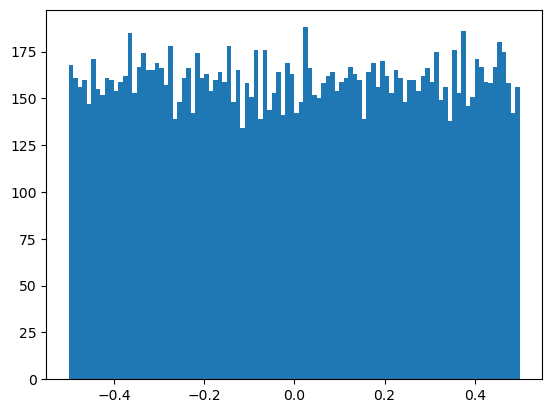

In [54]:
import glob
import matplotlib as mpl
files = glob.glob(os.path.join("../outputs/","**", "BI_channel_**_varying_grid_size.csv"), recursive = True)
for i,file in enumerate(files):
    df = pd.read_csv(file)
    plt.plot(df["grid_N"], df["1-rp"],marker='o')
    plt.plot(df["grid_N"], df["J"],marker='o')
    plt.show()
files = glob.glob(os.path.join("../outputs/","**", "J_90_N_grid_**.npy"), recursive = True)
cmap = plt.get_cmap("viridis")
grid_Ns = []
for i,file in enumerate(files):
    channel = int(file.split("channel_")[1].split("/")[0])
    grid_N = int(file.split("N_grid_")[1].split(".npy")[0])
    grid_Ns.append(grid_N)
    J_values = np.load(file)
    plt.plot(np.arange(len(J_values)), J_values, label=f"Channel {channel} grid N {grid_N}",c=cmap(i/len(files)))
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=mpl.colors.Normalize(vmin=min(grid_Ns), vmax=max(grid_Ns)))
cbar = plt.colorbar(sm, pad=0.01)
plt.show()
files = glob.glob(os.path.join("../outputs/","**", "functions_eff90_N_grid_**.npy"), recursive = True)
cmap = plt.get_cmap("viridis")
for i,file in enumerate(files):
    channel = int(file.split("channel_")[1].split("/")[0])
    grid_N = int(file.split("N_grid_")[1].split(".npy")[0])
    f1,f2 = np.load(file)
    window_size = len(f1)
    plt.plot(np.fft.fftfreq(window_size,1e-4)[:window_size//2], f1[:window_size//2], label=f"Channel {channel} grid N {grid_N}",c=cmap(i/len(files)),alpha=0.5)
    plt.plot(np.fft.fftfreq(window_size,1e-4)[:window_size//2], f2[:window_size//2], c=cmap(i/len(files)),alpha=0.5)

In [49]:
single_pulse_indexes =  [[126, 47, 77],
                         [394, 390, 240],
                         [33, 334, 322],
                         [71, 312, 199],
                         [101, 233, 71],
                         [253, 52, 147],
                         [238, 103, 6],
                         [295, 67, 199]]
channel = 19
pos_pulses = np.load(f"{BASE}/outputs/meanpulses_build/pos_pulses_rawdata/pos_pulses_channel_{channel}.npy")
file_name = ds.find_file(f"000813_20230628T161508_{channel:03}_000.bin")
dataset_pulse = ds.CachedBinaryDataset(file_name,window_size,positions=pos_pulses,win_shift_start = -window_size//2)
pulses_min_baseline = (dataset_pulse.data-dataset_pulse.data[:, :window_size//2-48].mean(dim=1,keepdim = True))
normalize_amp = torch.max(pulses_min_baseline,dim=1).values/ds.get_amp_Q_val(channel)
index = single_pulse_indexes[channels.index(channel)][0]
# plt.plot(pulses_min_baseline[index]/torch.max(pulses_min_baseline[index]),label='Selected pulse 0')
plt.loglog(np.abs(np.fft.fft(pulses_min_baseline[index]/torch.max(pulses_min_baseline[index]))),label='Selected pulse 0')
index = single_pulse_indexes[channels.index(channel)][1]
# plt.plot(pulses_min_baseline[index]/torch.max(pulses_min_baseline[index]),label='Selected pulse 1')
plt.loglog(np.abs(np.fft.fft(pulses_min_baseline[index]/torch.max(pulses_min_baseline[index]))),label='Selected pulse 1')
index = single_pulse_indexes[channels.index(channel)][2]
# plt.plot(pulses_min_baseline[index]/torch.max(pulses_min_baseline[index]),label='Selected pulse 2')
plt.loglog(np.abs(np.fft.fft(pulses_min_baseline[index]/torch.max(pulses_min_baseline[index]))),label='Selected pulse 2')
plt.legend()
plt.show()

0        0.293780
1       -0.265171
2        0.017496
3       -0.128942
4       -0.107522
           ...   
15995   -0.491282
15996    0.006327
15997   -0.298081
15998    0.155281
15999   -0.319520
Name: dt, Length: 16000, dtype: float64

In [ ]:

rms_s = np.array([29,35,40,50,70,95,23,18,16-1.3])*1e-5
signal_amps =  [0.028,  0.033,  0.035,  0.035,   0.04,  0.031,  0.022,  0.018,  0.015]
measurements = [779,    780,    781,    782,    783,    784,    785,    786,    787]
channel = 3

# channel = 5
# measurements = [767,768,769,770,771,772,773,774,775]
# rms_s = np.array([3,3.5,4,5,6.5,8,2.7,2.2,1.9])*1e-4
# signal_amps = [0.085,0.1,0.11,0.13,0.143,0.137,0.063,0.047,0.039]
len_d = 450
popts = []
fig,ax2 = plt.subplots(1,figsize=(10,6))
popt_list = []
signal_amps_meas = []
fs_val = 5000
NTL_amp = 0
nps_s = []
biais_current = [2.89,2.036,1.57,1.0,0.549,0.279,4.8383,7.696,10]

for meas in measurements:
    signal_amp = signal_amps[measurements.index(meas)]
    rms_thr = rms_s[measurements.index(meas)]
    file_name = ds.find_file(f"000{meas}*_{channel:03}_000.bin")
    dataset = ds.CachedBinaryDataset(file_name,2048,positions=2048*np.arange(len_d,dtype=int)+2)
    nps = an.create_NPS_torch(dataset,n_deriv=0,rms_thr=rms_thr, batch_size=2048, window_fct=np.hanning,
                                          use_loader=False, device='cpu').astype(np.float64)
    #nps.tofile(f"../outputs/NPS_study/NPS_measurement_{meas}_channel{channel}.bin")
    
    sel = torch.std(dataset.data,dim=1).numpy()>rms_thr*5
    trigpos = dataset.data[sel].argmax(dim=1) + np.argwhere(sel)[:,0]*2048 + 2
    trigpos = trigpos[torch.diff(trigpos,prepend =torch.tensor([-torch.inf]))>2000]
    dataset_pulse = ds.CachedBinaryDataset(file_name,2048,positions=trigpos.numpy(),win_shift_start = -1024)
    mean_pulse, pulses = an.build_mean_pulse_filteralignement_from_raw(dataset_pulse, rms_thr = rms_thr,
                                                              nps = nps, batch_size = 2048,
                                                              pulse_start_pos=-100, pulse_end_pos=4096,
                                                              amplitude_bounds=(signal_amp-0.01,signal_amp+0.01),
                                                              return_amp = False,return_pulses = True,
                                                              device = 'cpu', use_loader = False)
    #mean_pulse.numpy().tofile(f"../outputs/meanpulses_build/meanpulse_measurement_{meas}_channel{channel}.bin")


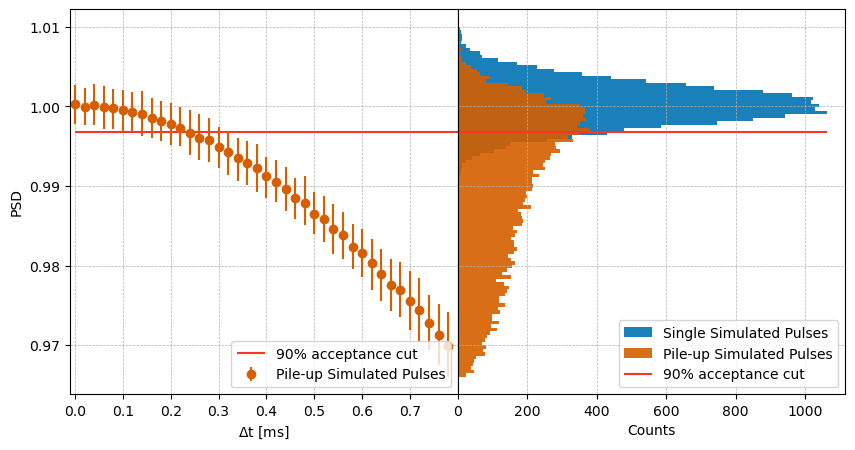

In [71]:

channels = [3,5,9,11,13,15,17,19]
window_size = 4096
len_d = 1024*4
# meas = 815
# rms_thr_list =np.array([2.4,3.0,6.4,7.0,7.0,5.5,3.3,18])*1e-4
meas = 830
rms_thr_list =np.array([1.94,2.4,4.2,4.0,3.4,3.6,2.7,14])*1e-4
for channel in channels:
    file_name = ds.find_file(f"000{meas}*_{channel:03}_000.bin")
    dataset = ds.CachedBinaryDataset(file_name,window_size,positions=window_size*np.arange(len_d,dtype=int)+2)
    # stds = torch.std(dataset.data,dim=1).numpy()*1e4
    # print(np.percentile(stds,1),np.percentile(stds,90))
    # plt.hist(stds,bins=100,range=(np.percentile(stds,1),np.percentile(stds,90)),alpha=0.5,label=f"Channel {channel}")
    # plt.show()
    rms_thr = rms_thr_list[channels.index(channel)]
    nps = an.create_NPS_torch(dataset,n_deriv=0,rms_thr=rms_thr, batch_size=2048, window_fct=np.hanning,
                                          use_loader=False, device='cpu').astype(np.float64)
    sel = torch.std(dataset.data,dim=1).numpy()>rms_thr*5
    trigpos = dataset.data[sel].argmax(dim=1) + np.argwhere(sel)[:,0]*window_size + 2
    trigpos = trigpos[torch.diff(trigpos,prepend =torch.tensor([-torch.inf]))>window_size*2]
    dataset_pulse = ds.CachedBinaryDataset(file_name,window_size,positions=trigpos.numpy(),win_shift_start = -window_size//2)
    mean_pulse, pulses = an.build_mean_pulse_filteralignement_from_raw(dataset_pulse, rms_thr = rms_thr,
                                                              nps = nps, batch_size = 2048,
                                                              pulse_start_pos=-100, pulse_end_pos=2048,
                                                              amplitude_bounds=(0.1,5),
                                                              return_amp = False,return_pulses = True,
                                                              device = 'cpu', use_loader = False)
    pulses_norm = pulses/torch.max(pulses,dim=1).values[:,None]
    chi2 = torch.mean((pulses_norm-mean_pulse)**2,dim=1)
    pulses_norm = pulses_norm[chi2<0.0002]
    mean_pulse = torch.mean(pulses_norm,dim=0)
    # plt.plot(pulses_norm.T,color='gray',alpha=0.3)
    # plt.plot(mean_pulse,label=f"Channel {channel}")
    # 
    # plt.xlim(1800,2700)
    # plt.show()
    nps.astype(np.float64).tofile(f"../outputs/NPS_study/NPS_measurement_{meas}_channel{channel}.bin")
    mean_pulse.numpy().astype(np.float64).tofile(f"../outputs/meanpulses_build/meanpulse_measurement_{meas}_channel{channel}.bin")
    fig,(ax1,ax2) = plt.subplots(1,2,figsize=(12,5))
    ax1.loglog(np.fft.rfftfreq(window_size,1e-4),nps[:window_size//2+1],label=f"Channel {channel}")
    ax1.set_title(f"NPS Channel {channel}")
    ax1.set_xlabel("Frequency (Hz)")
    ax1.set_ylabel("NPS (a.u.)")
    ax1.legend()
    ax2.loglog(np.fft.rfftfreq(window_size,1e-4),np.abs(np.fft.fft(mean_pulse))[:window_size//2+1],label=f"Channel {channel}")
    

In [ ]:
mp = np.load("../outputs/meanpulses_build/channel3_meanpulse_raw.npy")
mp = mp/np.max(mp)
plt.plot(np.arange(-len(mp)//2,len(mp)//2)*1e-1,mp, label='Normalized Pulse event')
plt.fill_betweenx(np.array([-0.11,1.1]),-8e-1,8e-1,color='red',alpha=0.3, label='$\Delta t$ window : [-0.8 ms, 0.8 ms]')
plt.xlim(-5,20)
plt.ylim(-0.04,1.1)
plt.yticks([])
plt.legend(fontsize=12)
plt.xlabel("Time (ms)", fontsize=14)
plt.xticks(fontsize=12)
plt.show()

In [ ]:
measurements = [779,    780,    781,    782,    783,    784,    785,    786,    787]# + [767,768,769,770,771,772,773,774,775]
bias_current = [2.89,2.036,1.57,1.0,0.549,0.279,4.8383,7.696,10]#+ [4.8383,7.696,10,2.89,2.036,1.57,1.0,0.549,0.279]
channel = 3
fig,ax = plt.subplots(1,1,figsize=(12,9))
ref_LED_amp = [0.032891195]*9 + [0.13]*9
ref_sensitivity_list = [1.4]*9 + [2.0]*9
Gains_80V_list = [13.6]*9 + [10.6]*9
NTL_noise_factor_list = [1e-7] *9 + [0.3e-7]*9
for idx in np.argsort(bias_current):
    meas,b = measurements[idx], bias_current[idx]
    # signal_amp = ref_amplitude * WP_gain * Gains_80V
    mean_pulse_filtered = np.fromfile(f"{BASE}/outputs/meanpulses_build/meanpulse_measurement_{meas}_channel{channel}.bin")
    nps = (np.fromfile(f"{BASE}/outputs/NPS_study/NPS_measurement_{meas}_channel{channel}.bin"))
    l,= plt.loglog(np.fft.rfftfreq(len(mean_pulse_filtered),1e-4),nps[:len(mean_pulse_filtered)//2+1],label=f"{b} nA")
    plt.loglog(np.fft.rfftfreq(len(mean_pulse_filtered),1e-4),np.abs(np.fft.fft(mean_pulse_filtered))[:1025],c=l.get_color())
plt.xlabel("Frequency (Hz)")
plt.ylabel("NPS (a.u.)")
plt.legend()


In [ ]:
measurements = [767,768,769,770,771,772,773,774,775]
channel = 5
fig,ax = plt.subplots(1,1,figsize=(12,9))
ref_LED_amp = [0.032891195]*9 + [0.13]*9
ref_sensitivity_list = [1.4]*9 + [2.0]*9
Gains_80V_list = [13.6]*9 + [10.6]*9
NTL_noise_factor_list = [1e-7] *9 + [0.3e-7]*9
for idx in np.argsort(bias_current):
    meas,b = measurements[idx], bias_current[idx]
    # signal_amp = ref_amplitude * WP_gain * Gains_80V
    mean_pulse_filtered = np.fromfile(f"{BASE}/outputs/meanpulses_build/meanpulse_measurement_{meas}_channel{channel}.bin")
    nps = (np.fromfile(f"{BASE}/outputs/NPS_study/NPS_measurement_{meas}_channel{channel}.bin"))
    l,= plt.loglog(np.fft.rfftfreq(len(mean_pulse_filtered),1e-4),nps[:len(mean_pulse_filtered)//2+1],label=f"{b} nA")
    plt.loglog(np.fft.rfftfreq(len(mean_pulse_filtered),1e-4),np.abs(np.fft.fft(mean_pulse_filtered))[:1025],c=l.get_color())
plt.xlabel("Frequency (Hz)")
plt.ylabel("NPS (a.u.)")
plt.legend()

In [ ]:
LED_amp = ([0.028401334, 0.032891195, 0.035842195, 0.038979053, 0.03883822, 0.031177562, 0.021730503, 0.016601065, 0.0141078625]+
           [0.085,0.1,0.11,0.13,0.143,0.137,0.063,0.047,0.039])

In [ ]:
plt.scatter(bias_current,[0.028401334, 0.032891195, 0.035842195, 0.038979053, 0.03883822, 0.031177562, 0.021730503, 0.016601065, 0.0141078625],label ="Channel 3, detector 5")
plt.scatter(bias_current,[0.085,0.1,0.11,0.13,0.143,0.137,0.063,0.047,0.039],label ="Channel 5, detector 9")
plt.legend()

In [ ]:
df = pd.read_csv(f"../outputs/Systematics/BI_WP.csv")
df["BI"] = fn.K * df["J_value"]*1e5
df


In [ ]:
file_name = ds.find_file(f"000{meas}*_{channel:03}_000.bin")
len(ds.load_binary_file(file_name))/5000

In [ ]:
channels = [3, 5, 9, 11, 13, 15, 17, 19]

f1_all, f2_all = [], []
fn.K
fig, ax = plt.subplots(figsize = (8, 6))

for ch in channels:
    f1, f2 = np.load(f"../outputs/Pileup_filter_functions/channel_{ch}/functions_eff90_V2.npy")
    freq = np.fft.fftfreq(len(f1), d = 1e-4)
    l,=ax.loglog(freq[:1000], f1[:1000], alpha = 0.1)
    ax.loglog(freq[:1000], f2[:1000], alpha = 0.5, color = l.get_color())
    ax.axvline(freq[np.where((np.mean(f2[800:1000])-f2[:1000])>0)[0][0]], color = l.get_color())
    print(freq[np.argmax(f1)],np.max(f1))
    #print(np.mean(f2[800:1000]),freq[np.where((np.mean(f2[800:1000])-f2[:1000])>0)[0][0]])

In [ ]:
df = pd.read_csv("../outputs/BI_results_base.csv")
df["detector_id"] = df["channel"].apply(lambda x: channel_ID[channels.index(x)])

df.sort_values("detector_id",inplace = True)
df["BI"]*=1e5
df["BI_uncertainty"]*=1e5
df["BI"].mean()

In [ ]:
np.mean([8.4,8.4,6.0,6.7,7.4,6.4,7.0,7.0])
# np.mean([10.2,10.1,6.7,6.8,7.8,7.8,7.7,8.3,7.8])

In [ ]:
(7.16-5.64)/7.16*100

In [ ]:
df_w = pd.read_csv("../outputs/Systematics/BI_window_size.csv")
df_w = df_w.loc[df_w['window_size']>=2048]
w = df_w.groupby("channel").apply(lambda x: (x["BI"].max()-x["BI"].min())/2*1e5*0.67)
df_pos = pd.read_csv("../outputs/Systematics/BI_frac_4Pole_Bessel.csv")
pos = df_pos.groupby("channel").apply(lambda x: (x["BI"].max()-x["BI"].min())/2*1e5*0.67)
df_grid = pd.read_csv("../outputs/Systematics/BI_varying_grid_size.csv")
df_grid = df_grid.loc[df_grid['grid_N_t']>=100]
grid = df_grid.groupby("channel").apply(lambda x: (x["J"].max()-x["J"].min())/2*1e5*fn.K*0.67)

df_1 = pd.read_csv("../outputs/Systematics/BI_meanpulse_test.csv")
df_2 = pd.read_csv("../outputs/Systematics/BI_meanpulses_test_2.csv")
df_injection = pd.concat((df_1, df_2))
df_injection = df_injection.loc[df_injection["meanpulse_type"]!="fit"]
# mp_sys = df_injection.groupby("channel").apply(lambda x: (x.loc[x["meanpulse_type"]=="mean","BI"]-x["BI"].min())*1e5*0.67)
mp_sys = df_injection.groupby("channel").apply(lambda x: np.abs(x.loc[x["meanpulse_type"]=="mean","BI"]-x["BI"].max())*1e5*0.67)
df_sys = pd.DataFrame({"channel":w.index,
                       "window_size_sys":w.values,
                       "pole_filter_sys":pos.values,
                       "grid_size_sys":grid.values,
                       "meanpulse_sys":mp_sys.values})
df_sys["total_sys"] = np.sqrt(df_sys["window_size_sys"]**2+
                               df_sys["pole_filter_sys"]**2+
                               df_sys["grid_size_sys"]**2+
                               df_sys["meanpulse_sys"]**2)
df_sys["detector_id"] = df_sys["channel"].apply(lambda x: channel_ID[channels.index(x)])

df_sys = df_sys.sort_values("detector_id")
df_sys


In [ ]:
df_injection["detector_id"] = df_injection["channel"].apply(lambda x: channel_ID[channels.index(x)])

df_injection.loc[df_injection["meanpulse_type"]=="mean","BI"].mean()*1e5


In [ ]:
channel_ID,channels

In [ ]:
df_1 = pd.read_csv("../outputs/Systematics/BI_meanpulse_test.csv")
df_2 = pd.read_csv("../outputs/Systematics/BI_meanpulses_test_2.csv")
df_injection = pd.concat((df_1, df_2))
print(df_injection.groupby("channel")["BI"].min()*1e5)
print(df_injection.loc[df_injection["meanpulse_type"]=="raw",["channel","BI"]]*1e5)

In [ ]:
df_injection[df_injection["channel"]==11]


In [ ]:
df_1 = pd.read_csv("../outputs/Systematics/BI_meanpulse_test.csv")
df_2 = pd.read_csv("../outputs/Systematics/BI_meanpulses_test_2.csv")
df_injection = pd.concat((df_1, df_2))
df_injection

In [ ]:
fig, ax = plt.subplots(figsize = (8, 6))
f1_all, f2_all = [], []
for ch in channels:
    f1, f2 = np.load(f"../outputs/Pileup_filter_functions/channel_{ch}/functions_eff90_base_true_mp.npy")
    f1_all.append(np.abs(f1))
    f2_all.append(np.abs(f2))

    freq = np.fft.fftfreq(len(f1), d = 1e-4)
    pos_freq = freq > 0
    gain_1000 = f1[freq>1000][0]
    gain_3000 = f1[freq>3000][0]
    db_1000 = 20*np.log10(gain_1000)
    db_3000 = 20*np.log10(gain_3000)
    change_db = db_3000 - db_1000
    freq_ratio = 3000 / 1000
    decades = np.log10(freq_ratio)
    print(change_db/decades, np.max(f1), ch)
    
    ax.plot(freq[pos_freq], f1[pos_freq], alpha = 0.1, color = "k")
    ax.plot(freq[pos_freq], f2[pos_freq], alpha = 0.1, color = "k")
from scipy.stats import pearsonr
ax.set_xscale("log")
ax.set_yscale("log")
gains_m1 = np.array(f1_all)
median_m1 = np.median(gains_m1, axis = 0)
r_squared_values = []
for detector_gains in gains_m1:
    r, _ = pearsonr(detector_gains, median_m1)
    r_squared_values.append(r**2)
mean_r2 = np.mean(r_squared_values)
gains_m2 = np.array(f2_all)
median_m2 = np.median(gains_m2, axis = 0)
print(f"Mean R² with median: {mean_r2:.3f}")
r_squared_values = []
for detector_gains in gains_m2:
    r, _ = pearsonr(detector_gains, median_m2)
    r_squared_values.append(r**2)
mean_r2 = np.mean(r_squared_values)
print(f"Mean R² with median: {mean_r2:.3f}")

In [ ]:
fn.calculate_K_factor(Activity = 3.09E-03,  # Activity in Bq (N/s)
                        LMO_MASS = 0.308,  # Mass of LMO in kg
                        second_in_year = 3600 * 24 * 365,  # Number of seconds in a year
                        Probability = 3.41E-04,  # Given probability factor
                        correction_factor = 1,  # Factor for corrections
                        dt = 0.8 , # Example exposure time in seconds
                        milliseconds_in_second = 1000)/fn.calculate_K_factor(Activity = 2.93E-03,  # Activity in Bq (N/s)
                        LMO_MASS = 0.28,  # Mass of LMO in kg
                        second_in_year = 3600 * 24 * 365,  # Number of seconds in a year
                        Probability = 3.41E-04,  # Given probability factor
                        correction_factor = 1,  # Factor for corrections
                        dt = 0.8 , # Example exposure time in seconds
                        milliseconds_in_second = 1000)

In [ ]:
fn.K - fn.calculate_K_factor(Activity = 3.09E-03,  # Activity in Bq (N/s)
                        LMO_MASS = 0.308,  # Mass of LMO in kg
                        second_in_year = 3600 * 24 * 365,  # Number of seconds in a year
                        Probability = 3.41E-04,  # Given probability factor
                        correction_factor = 1,  # Factor for corrections
                        dt = 0.8 , # Example exposure time in seconds
                        milliseconds_in_second = 1000)


In [ ]:
fn.calculate_K_factor(Activity = 2.93E-03,  # Activity in Bq (N/s)
                        LMO_MASS = 0.28,  # Mass of LMO in kg
                        second_in_year = 3600 * 24 * 365,  # Number of seconds in a year
                        Probability = 3.41E-04,  # Given probability factor
                        correction_factor = 1,  # Factor for corrections
                        dt = 0.8 , # Example exposure time in seconds
                        milliseconds_in_second = 1000)


In [ ]:
from torch.utils.data import DataLoader
path = "/media/mp274748/Transcend/data/Ulysse/RUN121"
file_name_list = []
rms_thr_list = []
amp_max_list = []
for file_name in os.listdir(path):
    file_path = ds.find_file(os.path.join(path,file_name))
    if file_path[-7:]!="000.bin":
        continue
    dataset = ds.BinaryDataset(file_path, 4096)
    dl =DataLoader(dataset, batch_size=4096, shuffle=False)
    #fig,(ax1,ax2) = plt.subplots(1,2,figsize=(10,6))
    for pulses in dl:
        std = pulses.std(dim=1)
    rms_thr_list.append(np.percentile(std,70))
    file_name_list.append(file_name)
    nps = an.create_NPS_torch(dataset,n_deriv=0,rms_thr=np.percentile(std,70), batch_size=2048, window_fct=np.hanning,
                                          use_loader=True, device='cpu').astype(np.float64)
    np.save(f"/media/mp274748/Transcend/data/Ulysse/RUN121/NPS_RUN121_{file_name.split('.bin')[0]}.npy",nps)
    #ax1.loglog(nps)
    #nps = np.load(f"/media/mp274748/Transcend/data/Ulysse/RUN121/NPS_RUN121_{file_name.split('.bin')[0]}.npy")
    # plt.show()
    arg_max = torch.argmax(pulses[std.numpy()>np.percentile(std,70)*4],dim=1).numpy()
    pos_pulses = dataset.positions[std.numpy()>np.percentile(std,70)*4]
    pos_pulses = pos_pulses[np.diff(pos_pulses,prepend =torch.tensor([-torch.inf]))>5000]+arg_max[np.diff(pos_pulses,prepend =torch.tensor([-torch.inf]))>5000]
    pos_pulses = pos_pulses[dataset.positions[-1]-pos_pulses>2048]
    dataset = ds.BinaryDataset(file_path, 4096,positions=pos_pulses,win_shift = 2048)
    if len(dataset)==0:
        amp_max_list.append(0)
        continue
    meanpulse,amp = an.build_mean_pulse_filteralignement_from_raw(dataset, rms_thr = np.percentile(std,70),
                                                              nps = nps, batch_size = 2048,
                                                              pulse_start_pos=-40, pulse_end_pos=300,
                                                              amplitude_bounds=(0.1,5),
                                                              return_amp = True,return_pulses = False,
                                                              device = 'cpu', use_loader = False)
    #ax2.plot(pulse.T/torch.max(pulse,dim=1).values,color='gray',alpha=0.3)
    try:
        hist, bin = np.histogram(amp,bins=50,range=(np.percentile(amp,10),np.percentile(amp,90)))
        amp_max = bin[np.argmax(hist)]
    except:
        amp_max = 0
    amp_max_list.append(amp_max)
    #ax2.plot(meanpulse.numpy())
    np.save(f"/media/mp274748/Transcend/data/Ulysse/RUN121/MP_RUN121_{file_name.split('.bin')[0]}.npy",meanpulse)
    print(file_name_list,rms_thr_list,amp_max_list)
    np.savetxt("/media/mp274748/Transcend/data/Ulysse/RUN121/rms_amp_RUN121.txt",np.column_stack([file_name_list,rms_thr_list,amp_max_list]),fmt="%s")      

In [ ]:
df = pd.read_csv("/media/mp274748/Transcend/data/Ulysse/RUN121/rms_amp_RUN121.txt",header=None,names=["file_name","rms_thr","amp_max"],sep=" ")
df["channel"] = df["file_name"].apply(lambda x: int(x.split("_")[2]))
df["meas"] = df["file_name"].apply(lambda x: int(x.split("_")[0]))
df.sort_values("meas",inplace = True)
df.to_csv("/media/mp274748/Transcend/data/Ulysse/RUN121/rms_amp_RUN121.csv",index=False)

In [ ]:
test = np.loadtxt("/media/mp274748/Transcend/data/Ulysse/RUN121/rms_amp_RUN121.csv",delimiter=",",dtype=str)

test

In [ ]:
for channel in df["channel"].unique():
    df_sub = df.loc[df["channel"]==channel]
    plt.loglog(df_sub["meas"],df_sub["rms_thr"].astype(float),marker='o',label=f'Channel {channel}')


In [ ]:
df = pd.read_csv(f"{BASE}/outputs/Systematics/BI_WP_RUN121_Ulysse.csv")
df_info = pd.read_csv("/media/mp274748/Transcend/data/Ulysse/RUN121/rms_amp_SNR_RUN121.csv")
fig,ax1 = plt.subplots(figsize=(10,5))
ax2 = ax1.twinx()
biais = np.array([0.5,1,2,3,4,5,6,7,8,10,12,14,16,18,20,22,24,26,29])
for channel in df["channel"].unique():
    if channel == 2:
        continue
    df_sub = df.loc[df["channel"]==channel]
    df_info_sub = df_info.loc[df_info["channel"]==channel]
    l,=ax1.plot(biais[df_sub["measurement"].astype(int)-1],df_sub["J_value"]*100,marker='o')
    ax2.plot(biais[df_info_sub["meas"].astype(int)-1],1/df_info_sub["SNR"],c=l.get_color(),marker='^',alpha=0.6)
    ax1.plot([],[],marker='s',label=f'Channel {channel}',c=l.get_color(),ms=12)
ax1.plot([],[],marker='o',label=r'$\langle \mathcal{M} \rangle$',c="k")
ax1.plot([],[],marker='^',label=f'1/SNR',c="k")
ax1.set_xlabel("biais [nA]")
ax1.set_ylabel(r"Global pile-up misidentification rate $\langle \mathcal{M} \rangle$ [%]")
ax2.set_ylabel("1/SNR (a.u.)")
ax1.set_xticks(biais.astype(int))
ax1.legend()
fig.savefig("/local/home/mp274748/Documents/these/figures/BI_vs_bias_current_RUN121.pdf", dpi = 300)

In [ ]:
df_info

In [ ]:
fig,ax1 = plt.subplots(figsize=(12,8))
biais = np.array([0.5,1,2,3,4,5,6,7,8,10,12,14,16,18,20,22,24,26,29])
for i in range(2,20):
    df_sub = df_info.loc[df_info["channel"]==6]
    amp=df_sub.loc[df_sub["meas"]==i,"amp_max"].values[0]
    print(amp)
    nps = np.load(glob.glob(f"/media/mp274748/Transcend/data/Ulysse/RUN121/NPS_RUN121_0000{i:02}_**_006_000.npy")[0])
    mp = nps = np.load(glob.glob(f"/media/mp274748/Transcend/data/Ulysse/RUN121/MP_RUN121_0000{i:02}_**_006_000.npy")[0])
    # plt.loglog(np.fft.rfftfreq(4096,1/10000),nps[:2049],label=f"{biais[i-1]} nA")
    plt.plot(amp*mp[2048-100:2048+300],label=f"{biais[i-1]} nA")
plt.legend()

In [ ]:
df_sub

In [ ]:
directory = "/media/mp274748/Transcend/data/Ulysse/RUN121/"
rms_amp_data = np.loadtxt(directory+"rms_amp_RUN121.csv",delimiter=",",dtype=str)[1:]
SNR_list = []
for data in rms_amp_data:
    file_name = data[0]
    meas = int(data[4])
    channel = int(data[3])
    amp = float(data[2])
    try:
        mean_pulse_filtered = np.load(directory+f"MP_RUN121_{file_name.split('.bin')[0]}.npy")
        nps = np.load(directory+f"NPS_RUN121_{file_name.split('.bin')[0]}.npy")
        S, w, H_unit = an.compute_H(mean_pulse_filtered, nps, np.hanning)
        SNR = amp*0.1*np.sqrt(np.sum(np.abs(S)**2/nps))
    except:
        SNR = 0
    SNR_list.append(SNR)
    

In [ ]:
len(SNR_list)
df_info["SNR"] = SNR_list
df_info.to_csv(directory+"rms_amp_SNR_RUN121.csv",index=False)

In [ ]:
df_info = pd.read_csv("/media/mp274748/Transcend/data/Ulysse/RUN121/rms_amp_RUN121.csv")
len(df_info)

In [ ]:
from utility.double_beta_spectrum import g
plt.plot(np.linspace(0,3.034*2,3034*2),g(np.linspace(0,3.034*2,3034*2))/np.sum(g(np.linspace(0,3.034*2,3034*2))))


In [ ]:
distrib = g(np.linspace(0,2,2000))
distrib[3033]/np.sum(distrib)*1e4

In [ ]:
from scipy.interpolate import interp1d
mp = np.load("../outputs/meanpulses_build/channel3_meanpulse_raw.npy")
mp = mp / np.max(mp)
mp_interp = interp1d(np.arange(len(mp)), mp, kind = 'cubic')
mp = mp_interp(np.linspace(0, len(mp) - 1, 10000))
fig, ax = plt.subplots(1, 1, figsize = (8, 6))
ax.plot(np.arange(- np.argwhere(mp>1e-2)[0], len(mp) - np.argwhere(mp>1e-2)[0]) * 4096 / 10000 * 1e-1, mp,
        label = 'Pulse impulse response s(t)',color="black")
ax.fill_betweenx(np.array([-0.11, 1.1]), -0e-1, 8e-1, color = 'green', alpha = 0.3,
                 label = '$\Delta t$ window: 0.8 ms')
ax.set_xlim(-5, 20)
ax.set_ylim(-0.04, 1.1)
plt.yticks(fontsize = 20)
plt.legend(fontsize = 19)
ax.set_xlabel("Time (ms)", fontsize = 20)
plt.xticks(fontsize = 20)
plt.xticks(np.arange(-5,20,1),minor=True)
plt.yticks(np.arange(-0.1,1,0.1),minor=True)
ax.grid(linestyle = '--', linewidth = 1)
ax.grid(which='minor', linestyle=':', linewidth=0.5)
fig.set_tight_layout(True)
fig.savefig("/local/home/mp274748/Documents/paper/pile_up_cupid/figures/meanpulse_with_dt_range.pdf", dpi = 300)
plt.show()


In [ ]:
df = pd.read_csv("../outputs/Systematics/BI_varying_grid_size.csv")
for channel in df["channel"].unique():
    df_sub = df.loc[df["channel"]==channel]
    plt.plot(df_sub["grid_N"],(df_sub["BI"]-df_sub["J"]*fn.K)/(df_sub["BI"]+df_sub["J"]*fn.K)*200,marker='o',label=f"Channel {channel}")
    
plt.ylabel("Relative difference\n(simulated − analytical BI) [%]")
plt.xlabel("Grid size N")

In [ ]:
df = pd.read_csv("../outputs/Systematics/BI_varying_grid_size.csv")
df = df[df["grid_N_t"]>2]
for channel in df["channel"].unique():
    df_sub = df.loc[df["channel"]==channel]
    plt.errorbar(df_sub["grid_N_t"],df_sub["BI"],df_sub["BI_uncertainty"],marker='o',label=f"Channel {channel}",ls="")
plt.xticks(df_sub["grid_N_t"][::2])
plt.xlabel("Grid size N")
plt.ylabel("BI [1e-5 cts/keV/kg/year]")
plt.grid()

In [ ]:
df["detector_id"] = df["channel"].apply(lambda x: channel_ID[channels.index(x)])
df.sort_values("detector_id", inplace=True)
df[df["grid_N"]==100]

In [ ]:
df = pd.read_csv("../outputs/Systematics/BI_varying_grid_size.csv")
df = df[df["grid_N_t"] == 100]
df["detector_id"] = df["channel"].apply(lambda x: channel_ID[channels.index(x)])
df["BI"]*=1e5
df.sort_values("detector_id", inplace=True)
df

In [ ]:
df = pd.read_csv("../outputs/Systematics/BI_varying_grid_size_full_channel3.csv")
df = df[df["channel"] == 3]
df = df[(df["grid_N_t"]>9)&(df["grid_N_r"]>9)]

heatmap_data = df.pivot(index="grid_N_t", columns="grid_N_r", values="BI")

plt.imshow(heatmap_data, origin="lower", aspect="auto",interpolation = "bilinear",cmap="viridis")
plt.colorbar(label="J")

plt.xticks(range(len(heatmap_data.columns)), heatmap_data.columns.astype(int),rotation=40)
plt.yticks(range(len(heatmap_data.index)), heatmap_data.index.astype(int),rotation=40)

plt.xlabel("grid_N_r")
plt.ylabel("grid_N_t")
plt.title("Grid Search Heatmap of J")

plt.show()


In [ ]:
files = glob.glob(f"{BASE}/outputs/**/BI_**.csv",recursive=True)
old_K = fn.calculate_K_factor(Activity = 3.09E-03,  # Activity in Bq (N/s)
                        LMO_MASS = 0.308,  # Mass of LMO in kg
                        second_in_year = 3600 * 24 * 365,  # Number of seconds in a year
                        Probability = 3.41E-04,  # Given probability factor
                        correction_factor = 1,  # Factor for corrections
                        dt = 0.8 , # Example exposure time in seconds
                        milliseconds_in_second = 1000)
import ast
for file in files:
    df = pd.read_csv(file, converters={"popt": ast.literal_eval})
    
    if "BI" in df.columns:
        df["BI"] *= fn.K/old_K
    if "BI_uncertainty" in df.columns:
        df["BI_uncertainty"] *= fn.K/old_K
    if "BI_err" in df.columns:
        df["BI_err"] *= fn.K/old_K
        df.rename(columns={"BI_err": "BI_uncertainty"})
    df.to_csv(file, index=False)

In [ ]:
old_K = fn.calculate_K_factor(Activity = 3.09E-03,  # Activity in Bq (N/s)
                        LMO_MASS = 0.308,  # Mass of LMO in kg
                        second_in_year = 3600 * 24 * 365,  # Number of seconds in a year
                        Probability = 3.41E-04,  # Given probability factor
                        correction_factor = 1,  # Factor for corrections
                        dt = 0.8 , # Example exposure time in seconds
                        milliseconds_in_second = 1000)

print(fn.K/old_K)

In [ ]:
data_noise, _ = ds.create_data_sets(3, {"data_name": ["000813_20230628T161508"],
                                                  "pos_name": ["pup_n1-d0_000813_20230628T161508"],
                                                  "specific_subdir": [""],
                                                  "full_info": [False]},
                                        win_length=4096, shift=0, pos_prefix="_bis",
                                        len_data=2 ** 13 + 2 ** 12, cached=False)

In [ ]:
plt.plot(data_noise[21],c="k",lw=0.5)
plt.axis('off')
plt.gca().set_position([0, 0, 1, 1])
plt.savefig("/local/home/mp274748/Documents/presentation/denoising/noise_6.svg")

In [ ]:
import sys
from pathlib import Path
# Add src to Python path dynamically
BASE = "../"
sys.path.append(str(BASE))
import time
import numpy as np
import src.analysis as an
import src.dataset as ds
import src.simulation as sim
from utility.double_beta_spectrum import pdf_ratio2b
import torch
from scipy.stats import norm
n_deriv = 0
window_size = 4096
meas_name = "000813_20230628T161508"
device = 'cuda' if torch.cuda.is_available() else 'cpu'
BIs = []
BI_uncertainties = []
channel_list = []
J_list = []
channels = [3, 5, 9, 11, 13, 15, 17, 19]
channel_ID = [5, 9, 11, 10, 4, 2, 12, 3]
StdCuts = [0.0003, 0.0004, 0.0008, 0.0006, 0.0012, 0.0007, 0.00035, 0.0025]
for channel, StdCut in zip(channels, StdCuts):
    meanpulse = np.fromfile(ds.find_file(f"{meas_name}_{channel:03}_???.bin_edmean.bin",
                                         specific_subdir="RUN9_pulse_injected_new/"))
    # Load datasets and channel specifications
    dataset_single_name = "pup_n1-d0_000813_20230628T161508"
    file_path_single, path_pos_single = ds.find_files(meas_name, dataset_single_name, channel,
                                                      specific_subdir="RUN9_pulse_injected_new/")
    data_single = ds.CachedBinaryDataset_withgenerated(file_path_single, path_pos_single, 4096,
                                                       pulse=meanpulse,
                                                       n_windows=10, win_shift=0)
    # data_single, data_pileup = ds.create_data_sets_denoise(channel, win_length=2000, shift=0, pos_prefix="_bis")
    nps_bis = np.load(f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_{meas_name}.npy")
    nps_bis *= (8. / 3.)  # Adjust for Hann window effect

    meanpulse_bis = meanpulse[np.argmax(meanpulse) - window_size // 2:np.argmax(meanpulse) + window_size // 2]
    signal_amp = ds.get_amp_Q_val(channel)

    # Loop over acceptance levels
    # acceptances = [0.7, 0.8, 0.84, 0.87, 0.9, 0.92, 0.93, 0.94, 0.95, 0.96, 0.99]
    acceptances = [0.9]
    for acceptance in acceptances:
        N_sigma = norm.ppf(1 - (1 - acceptance) * 100 / 100)
        S, w, H_unit = an.compute_H(meanpulse_bis, nps_bis, np.hanning)
        pulse = data_single[3].numpy()
        freq = np.fft.fftfreq(len(pulse), d=1e-4)
        pulse -= pulse[:100].mean()
        fpulse = np.fft.fft(pulse * np.hanning(len(pulse)))
        filter_fpulse = fpulse * H_unit
        filtered_pulse = np.fft.ifft(filter_fpulse*np.exp(1j*freq*2*np.pi*2048/10000)).real
    break
plt.plot(filtered_pulse)
plt.plot(pulse)


In [ ]:
fig, ax = plt.subplots(figsize=(8, 6))
t = np.arange(-len(pulse)//2,len(pulse)//2) * 1e-4
ax.plot(t,filtered_pulse*1e3, label="Original Pulse", color="k")
ax.set_xlabel("Time [s]", fontsize=14)
ax.set_ylabel("Amplitude [mV]", fontsize=14)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
# Optional: make axes slightly thicker (nicer for thesis)
ax.spines['left'].set_linewidth(1.2)
ax.spines['bottom'].set_linewidth(1.2)
fig.set_tight_layout(True)
fig.savefig("/local/home/mp274748/Documents/these/figures/waveform_filtered.pdf", dpi=300)


In [ ]:
# PARAMETERS
# ⚠️ ONLY THIS SECTION SHOULD BE MODIFIED FOR A NEW CHANNEL / RUN ⚠️
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. CHANNEL IDENTIFICATION
# ------------------------------------------------------------------------------
CHANNEL = 3 # ← Channel number to analyse (int)

# ------------------------------------------------------------------------------
# 2. TIME WINDOW PARAMETERS
# ------------------------------------------------------------------------------
WIN_LENGTH = 2048 # ← Number of samples per pulse window
window_size = 2048

WIN_SHIFT = 0 # ← Window offset relative to the trigger (in samples)
# Leave at 0 if the trigger is already well centred.

SAMPLING_DT = 1e-4 # ← Sampling time step in seconds

# ------------------------------------------------------------------------------
# 3. QUALITY AND SELECTION PARAMETERS
# ------------------------------------------------------------------------------
N_DERIV = 0 # ← Derivative order applied to the pulse before analysis
# 0 = raw pulse, 1 = first derivative

LEN_DATA = 2000 # ← Maximum number of events to load per dataset.

# ------------------------------------------------------------------------------
# 4. FILTER OPTIMISATION PARAMETERS
# ------------------------------------------------------------------------------
ACCEPTANCE = 0.90 # ← Target acceptance level for single events
# 0.90 = 90%, corresponds to N_sigma = 1.28

N_TRIALS = 1000 # ← Number of Adam optimisation steps

DT_MAX = 8e-4 # ← Maximum time delay between two sub-events (seconds)

N_T = 100 # ← Number of points on the time-delay grid for optimisation

N_R = 100 # ← Number of points on the energy-ratio grid for optimisation

# ------------------------------------------------------------------------------
# 5. BACKGROUND INDEX (BI) PARAMETERS
# ------------------------------------------------------------------------------
BATCH_SIZE = 512 # ← Batch size for PSD computation

K = fn.calculate_K_factor(
Activity = 3.09e-3, # ← Activity in Bq
LMO_MASS = 0.308, # ← Crystal mass in kg
Probability = 3.41e-4, # ← Random coincidence probability within the dt window
dt = 2, # ← Coincidence time window in seconds
)

# ------------------------------------------------------------------------------
# 6. DATASET DESCRIPTION (data file structure)
# ------------------------------------------------------------------------------
# dataset_dict describes the two binary files to load:
# - First entry : "single" event data (full_info=False)
# - Second entry : "pileup" event data (full_info=True)
# full_info=True means the .pos file contains dt, r, E (pileup parameters)
DATASET_DICT = {
"data_name": ["pup_n1-d0_000813_20230628T161508", # ← Single data file name
"pup_n1-d8_000813_20230628T161508"], # ← Pileup data file name
"pos_name": ["pup_n1-d0_000813_20230628T161508", # ← Single .pos file name
"pup_n1-d8_000813_20230628T161508"], # ← Pileup .pos file name
"specific_subdir":["RUN9_pulse_injected_new/", # ← Single subdirectory
"RUN9_pulse_injected_new/"], # ← Pileup subdirectory
"full_info": [False, True],
}

# ------------------------------------------------------------------------------
# 7. OUTPUT PATHS
# ------------------------------------------------------------------------------


# ==============================================================================
# END OF PARAMETERS SECTION
# ==============================================================================


# ==============================================================================
# MAIN FUNCTION
# ==============================================================================
# Automatic CPU / GPU selection
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if torch.cuda.is_available():
    torch.cuda.init()
channel = CHANNEL

meas_name = "000813_20230628T161508"
# - nps : Noise Power Spectrum (frequency-dependent noise variance)
# - S : FFT of the windowed mean pulse (spectral fingerprint of the signal)
# - w : angular frequency vector (rad/s)
# - H_unit : normalised Wiener filter H ∝ S*/NPS
# - pulse_factor: max amplitude of the mean pulse derivative (normalisation factor)
# - dmeanpulse : N_DERIV-th derivative of the normalised mean pulse
nps = np.load(f"{BASE}/outputs/NPS_study/NPS_channel{channel}_win{window_size}_{meas_name}.npy")
nps *= (8. / 3.)  # Adjust for Hann window effect

meanpulse = np.load(f"{BASE}/outputs/meanpulses_build/channel{channel}_meanpulse_raw.npy")
meanpulse = meanpulse[np.argmax(meanpulse) - window_size // 2:np.argmax(meanpulse) + window_size // 2]
S, w, H_unit = an.compute_H(meanpulse, nps_bis, np.hanning)
H_unit, S, nps, w, pulse_factor, dmeanpulse = ds.get_channel_specs(
        CHANNEL,
        n_deriv=N_DERIV,
        window_fct=np.hanning,
    )

nps *= (8. / 3.)  # Adjust for Hann window effect
# Convert to PyTorch tensors on the correct device
S_t = torch.as_tensor(S, device=DEVICE, dtype=torch.cfloat)
H_t = torch.as_tensor(H_unit, device=DEVICE, dtype=torch.cfloat)
w_t = torch.as_tensor(w, device=DEVICE, dtype=torch.float)
nps_t = torch.as_tensor(nps, device=DEVICE, dtype=torch.float)

print(f" → NPS, mean pulse and filter H loaded (WIN_LENGTH = {len(nps)})")

# --------------------------------------------------------------------------
# STEP 2 — LOAD DATASETS
# --------------------------------------------------------------------------
print("\n[2/4] Loading datasets...")


# --------------------------------------------------------------------------
# STEP 3 — OPTIMISE FILTERS f1, f2
# --------------------------------------------------------------------------
print("\n[3/4] Optimising filters...")

# optimize_filters maximises J = ⟨A(r, Δt)⟩ using Adam, where:
# A = probability that a pileup event (r, Δt) produces a PSD outside the single cut
# f1 = "pileup-sensitive" filter (its response depends on Δt)
# f2 = "reference" filter (close to the Wiener filter)
# PSD = Amp(f1) / Amp(f2) ≈ 1 for singles, ≠ 1 for pileups


t_grid = torch.linspace(0, DT_MAX, N_T, device=DEVICE, dtype=torch.float)
r_grid = torch.linspace(0, 0.5 , N_R, device=DEVICE, dtype=torch.float)

# Physical distribution over r (double-beta spectrum of Mo-100)
# Weights J according to the true probability of each ratio r
from utility.double_beta_spectrum import pdf_ratio2b

ratio_distribution = torch.tensor(
    pdf_ratio2b(r_grid.cpu().numpy()), device=DEVICE, dtype=torch.float
)
ratio_distribution /= ratio_distribution.mean()  # Discrete normalisation


# Physical distribution over r (double-beta spectrum of Mo-100)
# Weights J according to the true probability of each ratio r
from utility.double_beta_spectrum import pdf_ratio2b

f1_opt, f2_opt, J_history = an.optimize_filters(S_t,
                                                H_t,
                                                w_t,
                                                t=t_grid,
                                                r=r_grid,
                                                nps=nps_t,
                                                signal_amp=1,
                                                ratio_distribution=ratio_distribution,
                                                N_sigma=1.28,
                                                n_trials=N_TRIALS,
                                                verbose=True
    )



In [ ]:
meanpulse = np.load(f"{BASE}/outputs/meanpulses_build/channel{channel}_meanpulse_raw.npy")
plt.plot(meanpulse)